In [2]:
# Import libraries
import os
os.chdir("D:\\DESKTOP\\Current-Projects\\tbrucei_docking_data\\ML-steps")
os.listdir()

['catboost_info',
 'negative_mamalian.txt',
 'negative_rdkit_descriptors.csv',
 'positive_rdkit_descriptors.csv',
 'positive_tbrucie.txt',
 'rdkit-scaffold-splitting.ipynb',
 'scaffold_rdkit.csv',
 'tb-ml-random-CV-Features.ipynb.ipynb']

In [4]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.impute import SimpleImputer

from scipy.stats import pearsonr, spearmanr

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

In [5]:
# Load Dataset and prepare it
tb_pos = pd.read_csv("positive_rdkit_descriptors.csv", header=0)
tb_neg = pd.read_csv("negative_rdkit_descriptors.csv", header=0)
print('shape of tb_pos: ', tb_pos.shape, 'shape of tb_neg: ', tb_neg.shape)
pos_deltaG = pd.read_csv("positive_tbrucie.txt", header=0, sep=rf'\s+')
neg_deltaG = pd.read_csv("negative_mamalian.txt", header=0, sep=rf'\s+')
print('shape of pos_deltaG: ', pos_deltaG.shape, 'shape of neg_deltaG: ', neg_deltaG.shape)
scaffold_rdkit = pd.read_csv('scaffold_rdkit.csv', header=0, sep=',')
print('shape of scaffold_rdkit: ', scaffold_rdkit.shape)

shape of tb_pos:  (7084, 218) shape of tb_neg:  (5882, 218)
shape of pos_deltaG:  (7085, 2) shape of neg_deltaG:  (5882, 2)
shape of scaffold_rdkit:  (12966, 2)


In [6]:
# Checking top 10 rows of each data frame
print('Top 10 rows of tb_pos')
print(tb_pos.head(10))
print('#' * 80)
print("Top 10 rows of nb_pos")
print(tb_neg.head(10))
print('#' * 80)
print('TOP 10 rows of pos_deltaG')
print(pos_deltaG.head(10))
print('#' * 80)
print('Top 10 rows of neg_deltaG')
print(neg_deltaG.head(10))
print('#' * 80)
print('Top 10 rows of scaffold_rdkit')
print(scaffold_rdkit.head(10))

Top 10 rows of tb_pos
                Molecule  MaxAbsEStateIndex  MaxEStateIndex  \
0  ZINC000000000910.mol2          12.564424       12.564424   
1  ZINC000000001690.mol2           2.273608        2.273608   
2  ZINC000000029877.mol2          11.879815       11.879815   
3  ZINC000000033416.mol2          12.596609       12.596609   
4  ZINC000000034999.mol2          12.836321       12.836321   
5  ZINC000000040506.mol2          12.010189       12.010189   
6  ZINC000000041501.mol2          12.462234       12.462234   
7  ZINC000000041615.mol2          12.723689       12.723689   
8  ZINC000000041676.mol2          12.370950       12.370950   
9  ZINC000000045096.mol2          12.970061       12.970061   

   MinAbsEStateIndex  MinEStateIndex       qed        SPS    MolWt  \
0           0.009537       -4.488118  0.912652  11.526316  287.242   
1           1.335566        1.335566  0.550299  13.125000  244.384   
2           0.084418       -0.315370  0.793268   8.937500  278.109   
3   

In [8]:
# Remove '.mol2' suffix from column 'Molecule' in data frame tb_pos &tb_neg
tb_pos['Molecule'] = tb_pos['Molecule'].str.removesuffix('.mol2')
tb_neg['Molecule'] = tb_neg['Molecule'].str.removesuffix('.mol2')
# Merging two data frames based on a column value
df_pos = pd.merge(tb_pos, pos_deltaG, on='Molecule', how='inner')
df_neg = pd.merge(tb_neg, neg_deltaG, on='Molecule', how='inner')
# Print TOP 10 rows of each data frame
print(df_pos.head())
print('#' * 80)
print(df_neg.head())
print('#' * 80)

           Molecule  MaxAbsEStateIndex  MaxEStateIndex  MinAbsEStateIndex  \
0  ZINC000000000910          12.564424       12.564424           0.009537   
1  ZINC000000001690           2.273608        2.273608           1.335566   
2  ZINC000000029877          11.879815       11.879815           0.084418   
3  ZINC000000033416          12.596609       12.596609           0.129331   
4  ZINC000000034999          12.836321       12.836321           0.054074   

   MinEStateIndex       qed        SPS    MolWt  HeavyAtomMolWt  ExactMolWt  \
0       -4.488118  0.912652  11.526316  287.242         281.194  287.010757   
1        1.335566  0.550299  13.125000  244.384         232.288  244.038042   
2       -0.315370  0.793268   8.937500  278.109         270.045  276.985074   
3       -4.556286  0.696213  11.272727  314.223         305.151  314.062675   
4       -0.874413  0.579465  28.476190  306.789         287.637  306.102272   

   ...  fr_sulfonamd  fr_sulfone  fr_term_acetylene  fr_tetraz

In [9]:
print('Before combining, shapes of data frames: ', df_pos.shape, df_neg.shape)
df_tb = pd.concat([df_pos, df_neg], ignore_index=True)
print('Shape of combined data frame: ', df_tb.shape)
print('Shape of scaffold_rdkit: ', scaffold_rdkit.shape)
df_tb_scaffold = pd.merge(df_tb, scaffold_rdkit, on='Molecule', how='inner')
print('Shape of df_tb_scaffold: ', df_tb_scaffold.shape)
# Remove 'Molecule' column from the data frame
new_df_tb_scaffold = df_tb_scaffold.drop(columns='Molecule')
print('Shpae of new_df_tb_scaffold: ', new_df_tb_scaffold.shape)

Before combining, shapes of data frames:  (7084, 219) (5882, 219)
Shape of combined data frame:  (12966, 219)
Shape of scaffold_rdkit:  (12966, 2)
Shape of df_tb_scaffold:  (12966, 220)
Shpae of new_df_tb_scaffold:  (12966, 219)


In [10]:
# Checking missing values from each feature
print('Checking missing values: ', new_df_tb_scaffold.isnull().sum()[new_df_tb_scaffold.isnull().sum() > 0])
print('Checking missing values in scaffold_rdkit: ', scaffold_rdkit.isnull().sum()[scaffold_rdkit.isnull().sum() > 0])
# print the list of missing values rows
new_df_tb_scaffold[new_df_tb_scaffold.isna().any(axis=1)]

Checking missing values:  Scaffold    41
dtype: int64
Checking missing values in scaffold_rdkit:  Scaffold    41
dtype: int64


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff,Scaffold
480,9.960733,9.960733,2.109169,-2.500926,0.346644,19.428571,208.122,200.058,208.023014,82,...,0,0,0,0,0,0,0,0,2.0,NaN
502,10.199306,10.199306,1.620556,-3.460648,0.447381,16.714286,205.098,200.058,205.000088,80,...,0,0,0,0,0,0,0,0,2.1,NaN
503,10.199306,10.199306,1.620556,-3.460648,0.447381,16.714286,205.098,200.058,205.000088,80,...,0,0,0,0,0,0,0,0,2.5,NaN
504,10.199306,10.199306,1.620556,-3.460648,0.447381,16.714286,205.098,200.058,205.000088,80,...,0,0,0,0,0,0,0,0,2.2,NaN
521,11.049541,11.049541,0.801435,-2.443773,0.512224,13.800000,219.169,208.081,219.051026,86,...,0,0,0,0,0,0,0,0,1.8,NaN
530,11.133526,11.133526,0.038241,-0.655093,0.296936,9.500000,200.234,184.106,200.104859,80,...,0,0,0,0,0,0,0,0,1.8,NaN
534,11.552917,11.552917,0.070185,-1.775949,0.503025,13.866667,216.233,200.105,216.099774,86,...,0,0,0,0,0,0,0,0,1.8,NaN
542,11.050970,11.050970,1.417502,-3.449583,0.295459,15.166667,260.158,252.094,260.029162,100,...,0,0,0,0,0,0,0,0,2.1,NaN
543,10.646458,10.646458,0.236019,-3.006273,0.467529,16.125000,231.180,220.092,231.052123,92,...,0,0,0,0,0,0,0,0,1.9,NaN
547,10.936855,10.936855,0.080150,-1.686764,0.487010,14.533333,215.269,196.117,215.128883,88,...,0,0,0,0,0,0,3,0,1.9,NaN


In [11]:
# Delete missing values
new_df_tb_scaffold.dropna(inplace=True)
print('Shape of data frame after removing nulll values: ', new_df_tb_scaffold.shape)
# Check to list the missing values after deletion
new_df_tb_scaffold[new_df_tb_scaffold.isna().any(axis=1)]

Shape of data frame after removing nulll values:  (12925, 219)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff,Scaffold


In [12]:
# Checking column data types of df_tb
for col in new_df_tb_scaffold.columns:
    print(col, new_df_tb_scaffold[col].dtype)

MaxAbsEStateIndex float64
MaxEStateIndex float64
MinAbsEStateIndex float64
MinEStateIndex float64
qed float64
SPS float64
MolWt float64
HeavyAtomMolWt float64
ExactMolWt float64
NumValenceElectrons int64
NumRadicalElectrons int64
MaxPartialCharge float64
MinPartialCharge float64
MaxAbsPartialCharge float64
MinAbsPartialCharge float64
FpDensityMorgan1 float64
FpDensityMorgan2 float64
FpDensityMorgan3 float64
BCUT2D_MWHI float64
BCUT2D_MWLOW float64
BCUT2D_CHGHI float64
BCUT2D_CHGLO float64
BCUT2D_LOGPHI float64
BCUT2D_LOGPLOW float64
BCUT2D_MRHI float64
BCUT2D_MRLOW float64
AvgIpc float64
BalabanJ float64
BertzCT float64
Chi0 float64
Chi0n float64
Chi0v float64
Chi1 float64
Chi1n float64
Chi1v float64
Chi2n float64
Chi2v float64
Chi3n float64
Chi3v float64
Chi4n float64
Chi4v float64
HallKierAlpha float64
Ipc float64
Kappa1 float64
Kappa2 float64
Kappa3 float64
LabuteASA float64
PEOE_VSA1 float64
PEOE_VSA10 float64
PEOE_VSA11 float64
PEOE_VSA12 float64
PEOE_VSA13 float64
PEOE_VSA14 floa

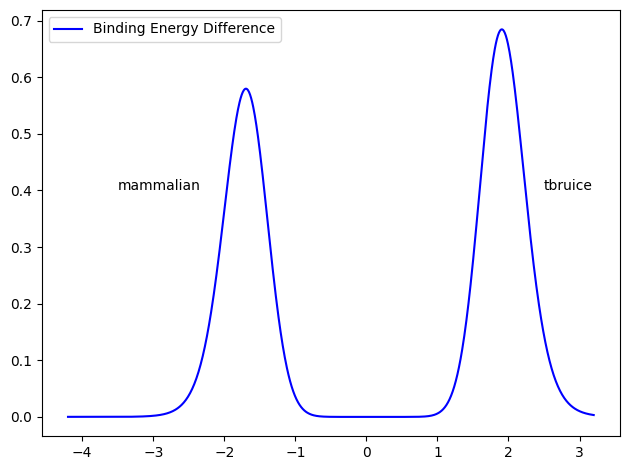

In [13]:
# distribution of 'BindingEnergyDiff' values
from scipy.stats import gaussian_kde

plt.figure()
def plot_values(data_frame):
    values = data_frame['BindingEnergyDiff'].dropna().values
    kde = gaussian_kde(values)
    x_vals = np.linspace(values.min(), values.max(), 1000)
    y_vals = kde(x_vals)
    return x_vals, y_vals

dx1, dy1 = plot_values(new_df_tb_scaffold)

plt.plot(dx1, dy1, color = 'blue', label='Binding Energy Difference')

plt.legend()
plt.text(-3.5, 0.4, 'mammalian')
plt.text(2.5, 0.4, 'tbruice')
plt.tight_layout()
plt.show()

In [14]:
# EXPLORATORY DATA ANALYSIS (EDA) 
# Finding relationship between features and remove constant value features, and \
# features containing correlation +1 or -1 values
columns_list = new_df_tb_scaffold.columns
uniq_value_columns = []
for col in columns_list:
    if new_df_tb_scaffold[col].nunique() == 1 :
        uniq_value_columns.append(col)

print('Uniq value columns: ', uniq_value_columns)
print('Total columns have unique value: ', len(uniq_value_columns))

# Remove uniq_value_columns from the data frame
print('Shape of data frame before deleting unique values: ', new_df_tb_scaffold.shape)
uniq_del_df_tb_scaffold = new_df_tb_scaffold.drop(columns=uniq_value_columns)
print('Shape of data frame after deleting unique values: ', uniq_del_df_tb_scaffold.shape)

# Calcualting data frame features correlation values for numeric features
# Calculate dimensions based on the number of features
num_features = len(uniq_del_df_tb_scaffold.select_dtypes(include=['number']).columns)
# Dynamically size the figure (e.g., 0.9 inches per feature)
plt.figure(figsize=(num_features * 0.9, num_features * 0.9))
sns.heatmap(uniq_del_df_tb_scaffold.corr(numeric_only=True), fmt=".2f", annot=True, cmap='coolwarm', vmin=-1, vmax=1)
# Remove limits on rows, columns, and width
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

uniq_del_df_tb_scaffold.corr(numeric_only=True).style.format("{: .2f}")


Uniq value columns:  ['NumRadicalElectrons', 'SMR_VSA8', 'SlogP_VSA9', 'NumAtomStereoCenters', 'NumUnspecifiedAtomStereoCenters', 'fr_isocyan', 'fr_isothiocyan', 'fr_thiocyan']
Total columns have unique value:  8
Shape of data frame before deleting unique values:  (12925, 219)
Shape of data frame after deleting unique values:  (12925, 211)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,MinAbsPartialCharge,FpDensityMorgan1,FpDensityMorgan2,FpDensityMorgan3,BCUT2D_MWHI,BCUT2D_MWLOW,BCUT2D_CHGHI,BCUT2D_CHGLO,BCUT2D_LOGPHI,BCUT2D_LOGPLOW,BCUT2D_MRHI,BCUT2D_MRLOW,AvgIpc,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,Chi2n,Chi2v,Chi3n,Chi3v,Chi4n,Chi4v,HallKierAlpha,Ipc,Kappa1,Kappa2,Kappa3,LabuteASA,PEOE_VSA1,PEOE_VSA10,PEOE_VSA11,PEOE_VSA12,PEOE_VSA13,PEOE_VSA14,PEOE_VSA2,PEOE_VSA3,PEOE_VSA4,PEOE_VSA5,PEOE_VSA6,PEOE_VSA7,PEOE_VSA8,PEOE_VSA9,SMR_VSA1,SMR_VSA10,SMR_VSA2,SMR_VSA3,SMR_VSA4,SMR_VSA5,SMR_VSA6,SMR_VSA7,SMR_VSA9,SlogP_VSA1,SlogP_VSA10,SlogP_VSA11,SlogP_VSA12,SlogP_VSA2,SlogP_VSA3,SlogP_VSA4,SlogP_VSA5,SlogP_VSA6,SlogP_VSA7,SlogP_VSA8,TPSA,EState_VSA1,EState_VSA10,EState_VSA11,EState_VSA2,EState_VSA3,EState_VSA4,EState_VSA5,EState_VSA6,EState_VSA7,EState_VSA8,EState_VSA9,VSA_EState1,VSA_EState10,VSA_EState2,VSA_EState3,VSA_EState4,VSA_EState5,VSA_EState6,VSA_EState7,VSA_EState8,VSA_EState9,FractionCSP3,HeavyAtomCount,NHOHCount,NOCount,NumAliphaticCarbocycles,NumAliphaticHeterocycles,NumAliphaticRings,NumAmideBonds,NumAromaticCarbocycles,NumAromaticHeterocycles,NumAromaticRings,NumBridgeheadAtoms,NumHAcceptors,NumHDonors,NumHeteroatoms,NumHeterocycles,NumRotatableBonds,NumSaturatedCarbocycles,NumSaturatedHeterocycles,NumSaturatedRings,NumSpiroAtoms,Phi,RingCount,MolLogP,MolMR,fr_Al_COO,fr_Al_OH,fr_Al_OH_noTert,fr_ArN,fr_Ar_COO,fr_Ar_N,fr_Ar_NH,fr_Ar_OH,fr_COO,fr_COO2,fr_C_O,fr_C_O_noCOO,fr_C_S,fr_HOCCN,fr_Imine,fr_NH0,fr_NH1,fr_NH2,fr_N_O,fr_Ndealkylation1,fr_Ndealkylation2,fr_Nhpyrrole,fr_SH,fr_aldehyde,fr_alkyl_carbamate,fr_alkyl_halide,fr_allylic_oxid,fr_amide,fr_amidine,fr_aniline,fr_aryl_methyl,fr_azide,fr_azo,fr_barbitur,fr_benzene,fr_benzodiazepine,fr_bicyclic,fr_diazo,fr_dihydropyridine,fr_epoxide,fr_ester,fr_ether,fr_furan,fr_guanido,fr_halogen,fr_hdrzine,fr_hdrzone,fr_imidazole,fr_imide,fr_ketone,fr_ketone_Topliss,fr_lactam,fr_lactone,fr_methoxy,fr_morpholine,fr_nitrile,fr_nitro,fr_nitro_arom,fr_nitro_arom_nonortho,fr_nitroso,fr_oxazole,fr_oxime,fr_para_hydroxylation,fr_phenol,fr_phenol_noOrthoHbond,fr_phos_acid,fr_phos_ester,fr_piperdine,fr_piperzine,fr_priamide,fr_prisulfonamd,fr_pyridine,fr_quatN,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff
MaxAbsEStateIndex,1.00,1.00,-0.31,-0.18,-0.11,-0.03,0.45,0.45,0.45,0.45,0.33,-0.02,0.02,0.34,-0.11,-0.08,-0.04,0.00,-0.11,0.19,-0.19,0.09,-0.17,0.07,-0.14,0.24,-0.25,0.40,0.46,0.42,0.42,0.44,0.39,0.40,0.35,0.35,0.28,0.30,0.22,0.24,-0.31,0.03,0.44,0.33,0.23,0.44,0.06,0.06,0.02,0.16,0.21,0.06,0.29,0.12,-0.04,-0.02,0.13,0.19,0.14,0.11,0.25,0.21,-0.01,-0.03,-0.04,0.07,0.11,0.30,-0.06,0.16,0.17,0.05,-0.01,0.15,0.20,0.03,0.14,0.26,0.00,-0.04,0.10,0.17,0.33,0.10,0.35,0.23,0.06,-0.00,0.20,0.16,-0.24,-0.04,0.18,-0.02,0.39,-0.15,-0.08,-0.19,0.22,-0.09,-0.00,-0.02,-0.05,0.45,-0.05,0.16,-0.05,0.20,0.09,0.32,0.28,-0.07,0.17,-0.04,0.07,-0.01,0.22,0.08,0.18,-0.06,0.14,0.04,0.03,0.29,0.25,0.21,0.41,-0.03,-0.06,-0.07,-0.13,-0.07,-0.13,-0.06,0.02,-0.07,-0.07,0.33,0.33,-0.03,-0.01,-0.03,-0.02,0.07,-0.13,0.03,0.01,0.09,-0.06,0.01,-0.03,-0.01,0.07,0.00,0.32,-0.00,0.12,0.05,-0.07,-0.05,0.04,0.28,0.00,0.04,-0.01,0.02,-0.02,0.04,0.03,-0.01,-0.05,0.15,0.02,-0.06,-0.07,0.12,0.09,0.09,0.01,-0.00,0.05,0.03,-0.01,-0.05,-0.02,-0.02,-0.03,0.00,-0.06,0.10,0.02,0.02,0.00,0.00,0.09,0.05,-0.00,-0.00,0.01,-0.08,0.03,0.08,-0.02,-0.02,-0.03,0.05,0.03,-0.02,0.06,-0.12
MaxEStateIndex,1.00,1.00,-0.31,-0.18,-0.11,-0.03,0.45,0.45,0.45,0.45,0.33,-0.02,0.02,0.34,-0.11,-0.08,-0.04,0.00,-0.11,0.19,-0.19,0.09,-0.17,0.07,-0.14,0.24,-0.25,0.40,0.46,0.42,0.42,0.44,0.39,0.40,0.35,0.35,0.28,0.30,0.22,0.24,-0.31,0.03,0.44,0.33,0.23,0.44,0.06,0.06,0.02,0.16,0.21,0.06,0.29,0.12,-0.04,-0.02,0.13,0.19,0.14,0.11,0.25,0.21,-0.01,-0.03,-0.04,0.07,

In [15]:
# Selecting Features which have correlation values > 0.95 or < -0.95
corr = uniq_del_df_tb_scaffold.corr(numeric_only=True)
pairs = []
threshold = 0.95

for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        value = corr.iloc[i, j]

        if abs(value) >= threshold:
            pairs.append([
                corr.index[i],
                corr.columns[j],
                value
            ])

high_corr_pairs = pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'Correlation'])

print('Shape of highly correlated features: ', high_corr_pairs['Feature_1'].unique())
print('#' * 80)
print('Shape of highly correlated features: ', high_corr_pairs['Feature_2'].unique())
print('#' * 80)
print(high_corr_pairs)

Shape of highly correlated features:  <StringArray>
[     'MaxAbsEStateIndex',                  'MolWt',         'HeavyAtomMolWt',
             'ExactMolWt',    'NumValenceElectrons',       'MaxPartialCharge',
       'MinPartialCharge',                   'Chi0',                  'Chi0n',
                  'Chi0v',                   'Chi1',                  'Chi2n',
                  'Chi2v',                  'Chi3n',                  'Chi3v',
                 'Kappa1',                 'Kappa2',                 'Kappa3',
              'LabuteASA',         'HeavyAtomCount',              'NHOHCount',
          'NumAmideBonds', 'NumAromaticCarbocycles',               'fr_Ar_NH',
                 'fr_COO',                 'fr_C_O',              'fr_phenol',
           'fr_phos_acid']
Length: 28, dtype: str
################################################################################
Shape of highly correlated features:  <StringArray>
[        'MaxEStateIndex',         'HeavyAtomMolWt',  

In [16]:
corr_columns = high_corr_pairs['Feature_1'].unique()
print('Shape before deleting corr_columns: ', uniq_del_df_tb_scaffold.shape)
corr_uniq_del_df_tb_scaffold = uniq_del_df_tb_scaffold.drop(columns=corr_columns)
print('Shape after deleting corr_columns: ', corr_uniq_del_df_tb_scaffold.shape)

Shape before deleting corr_columns:  (12925, 211)
Shape after deleting corr_columns:  (12925, 183)


In [17]:
corr_A = corr_uniq_del_df_tb_scaffold.corr(numeric_only=True)
pairs = []
threshold = 0.95

for i in range(len(corr_A.columns)):
    for j in range(i+1, len(corr_A.columns)):
        value = corr_A.iloc[i, j]

        if abs(value) >= threshold:
            pairs.append([
                corr_A.index[i],
                corr_A.columns[j],
                value
            ])

high_corr_pairs_A = pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'Correlation'])
high_corr_pairs_A

,Feature_1,Feature_2,Correlation


In [18]:
# Remove duplicates
print('Shape of before removing duplicates : ', corr_uniq_del_df_tb_scaffold.shape)
clean_df = corr_uniq_del_df_tb_scaffold.drop_duplicates(ignore_index=True)
print('Shape of clean_df dataframe: ', clean_df.shape)

Shape of before removing duplicates :  (12925, 183)
Shape of clean_df dataframe:  (12708, 183)


In [19]:
# 5-FOLD CROSS VALIDATION
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# SCORING
scoring = {
    "R2" : "r2",
    "RMSE" : "neg_root_mean_squared_error",
    "MAE" : "neg_mean_absolute_error"
}

In [21]:
#=========================================================
# MODEL 1: XGBOOST
#=========================================================
xgb_model = XGBRegressor(
    objective = "reg:squarederror",
    random_state = 42,
    tree_method="hist"
)

xgb_param_grid = {
    "n_estimators" : [200, 400, 600, 800, 1000],
    "max_depth" : [2, 3, 4, 5, 6, 8],
    "learning_rate" : [0.01, 0.03, 0.05, 0.1, 0.15],
    "subsample" : [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree" : [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight" : [1, 3, 5, 10],
    "reg_alpha" : [0, 0.01, 0.1, 1],
    "reg_lambda" : [0.1, 1, 5, 10]
}

xgb_search = RandomizedSearchCV(
    estimator = xgb_model,
    param_distributions = xgb_param_grid,
    n_iter = 50,
    scoring = scoring,
    cv = cv,
    verbose = 2, 
    random_state = 42,
    refit = "RMSE",
    return_train_score = True
)

#===============================================================
# MODEL 2: RANDOM FOREST
#===============================================================
rf_model = RandomForestRegressor(
    random_state = 42,
    )

rf_param_grid = {
    "n_estimators" : [300, 500, 800, 1000],
    "max_depth" : [None, 10, 20, 30, 40],
    "min_samples_split" : [2, 5, 10, 20],
    "min_samples_leaf" : [1, 2, 4, 8],
    "max_features" : [0.5, 0.7, 1.0, "sqrt"],
    "bootstrap" : [True, False]
}

rf_search = RandomizedSearchCV(
    estimator = rf_model,
    param_distributions = rf_param_grid,
    n_iter = 40,
    scoring = scoring,
    cv = cv,
    verbose = 2, 
    random_state = 42,
    refit = "RMSE",
    return_train_score = True
)

#=======================================================
# MODEL 3: SVR-RBF
#=======================================================
# Scaling is VERY import for SVR.
#
# Imputation + scaling are inside the Pipeline
# Therefore preprocessing is learned independently in each CV fold

svr_pipeline = Pipeline([
    ( "imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel = "rbf"))
])

svr_param_grid = {
    "svr__C" : [0.1, 1, 10, 50, 100, 500, 1000],
    "svr__gamma" : ["scale", "auto", 0.0001, 0.001, 0.01, 0.1],
    "svr__epsilon" : [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]
}

svr_search = RandomizedSearchCV(
    estimator = svr_pipeline,
    param_distributions = svr_param_grid,
    n_iter = 40, 
    scoring = scoring,
    cv = cv,
    verbose = 2,
    random_state = 42, 
    refit = "RMSE",
    return_train_score = True
)

#=========================================================
#  MODEL 4: CATBOOST
#=========================================================
cat_model = CatBoostRegressor(
    loss_function = "RMSE",
    random_seed = 42,
    verbose = False,
    thread_count =  -1
)

cat_param_grid = {
    "iterations" : [300, 500, 800, 1000],
    "depth" : [4, 5, 6, 7, 8, 10],
    "learning_rate" : [0.01, 0.03, 0.05, 0.1, 0.15],
    "l2_leaf_reg" : [1, 3, 5, 10, 20],
    "subsample" : [0.7, 0.8, 0.9, 1.0]
}

cat_search = RandomizedSearchCV(
    estimator = cat_model,
    param_distributions = cat_param_grid,
    n_iter = 40,
    scoring = scoring,
    cv = cv,
    verbose = 2,
    random_state = 42,
    refit = "RMSE",
    return_train_score = True
)

#===========================================================
# MODEL 5: LIGHTGBM
#===========================================================
lgb_model = LGBMRegressor(
    objective = "regression",
    random_state = 42,
    verbosity = -1
)

lgb_param_grid = {
    "n_estimators" : [100, 200, 400, 600, 800],
    "learning_rate" : [0.01, 0.03, 0.05, 0.1],
    "num_leaves" : [7, 15, 31, 50, 75],
    "max_depth" : [-1, 3, 5, 7, 10],
    "min_child_samples" : [5, 10, 20, 30, 50],
    "subsample" : [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree" : [0.6, 0.8, 1.0],
    "reg_alpha" : [0, 0.01, 0.1, 1],
    "reg_lambda" : [0, 0.1, 1, 5, 10]
}

lgb_search = RandomizedSearchCV(
    estimator = lgb_model,
    param_distributions = lgb_param_grid,
    n_iter = 40,
    scoring = scoring,
    cv = cv,
    verbose = 2,
    random_state = 42,
    refit = "RMSE",
    return_train_score = True
)

#==========================================================
# TRAIN / HYPERPARAMETER OPTIMIZATION
#==========================================================
models = {
    "XGBoost" : xgb_search,
    "SVR-RBF" : svr_search,
    "CatBoost" : cat_search,
    "LightGBM" : lgb_search,
    "Random Forest" : rf_search
}

results = {}
best_models = {}



In [22]:
# SEPARATE TARGET AND FEATURES
X = clean_df.drop(columns=["BindingEnergyDiff", "Scaffold"]).copy()
y = clean_df["BindingEnergyDiff"].copy()

print("\n Number of ML features: ")
print(X.shape[1])

print("\n Featurenames:")
print(X.columns.tolist())

#===================================================================
# 80/20 RANDOM TRAIN-TEST SPLIT
#===================================================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("\n Training set:")
print(X_train.shape)

print("\n Test set:")
print(X_test.shape)

#=========================================================
# IMPORTANT:
# X_test / y_test will NOT be used during model selection
#
# Everythin below uses ONLY X_train and y_train


 Number of ML features: 
181

 Featurenames:
['MaxEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'BCUT2D_MWHI', 'BCUT2D_MWLOW', 'BCUT2D_CHGHI', 'BCUT2D_CHGLO', 'BCUT2D_LOGPHI', 'BCUT2D_LOGPLOW', 'BCUT2D_MRHI', 'BCUT2D_MRLOW', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi1n', 'Chi1v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9', 'SMR_VSA1', 'SMR_VSA10', 'SMR_VSA2', 'SMR_VSA3', 'SMR_VSA4', 'SMR_VSA5', 'SMR_VSA6', 'SMR_VSA7', 'SMR_VSA9', 'SlogP_VSA1', 'SlogP_VSA10', 'SlogP_VSA11', 'SlogP_VSA12', 'SlogP_VSA2', 'SlogP_VSA3', 'SlogP_VSA4', 'SlogP_VSA5', 'SlogP_VSA6', 'SlogP_VSA7', 'SlogP_VSA8', 'TPSA', 'EState_VSA1', 'EState_VSA10', 'EState_VSA11', 'EState_VSA2', 'EState_VSA3', 'EState_VSA4', '

In [23]:
#================================================================
# RUN ALL MODELS
#=================================================================
for name, search in models.items():
    print("\n")
    print("=" * 80)
    print(f"TRAINING .......... {name}")
    print("=" * 80)

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    results[name] = {
        "Best CV RMSE" : search.best_score_,
        "Best Parameters" : search.best_params_
    }

    print("\n Best CV RMSE: ")
    print(search.best_score_)

    print("\n Best parameters:")
    print(search.best_params_)



TRAINING .......... XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   3.9s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   3.6s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   5.1s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   6.3s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=6, min_child_weight=1, n_estimators=1000, reg_alpha=0.01, reg_lambda=10, subsample=0.9; total time=   6.2s
[CV] END colsample_bytree=0.9, learning_rate=0.01, max_depth=3, min_

In [24]:
#======================================================================
# EVALUATION FUNCTION
#======================================================================
def evaluate_model(model, X_data, y_data):
    predictions = model.predict(X_data)

    r2 = r2_score(y_data, predictions)

    rmse = np.sqrt(mean_squared_error(y_data, predictions))

    mae = mean_absolute_error(y_data, predictions)

    pearson_r, pearson_p = pearsonr(y_data, predictions)

    spearman_rho, spearman_p = spearmanr(y_data, predictions)

    return {
        "R2" : r2,
        "RMSE" : rmse,
        "MAE" : mae,
        "Pearson_r" : pearson_r,
        "Pearson_p" : pearson_p,
        "Spearman_rho" : spearman_rho,
        "Spearman_p" : spearman_p
    }

In [25]:
#====================================================================
# FINAL TEST SET EVALUATION
#====================================================================
test_results = []

for name, model in best_models.items():
    print("\n")
    print("=" * 80)
    print(f"FINAL TEST EVALUATION: {name}")
    print("=" * 80)

    metrics = evaluate_model(model, X_test, y_test)

    print("\n R2: ")
    print(metrics["R2"])

    print("\n RMSE: ")
    print(metrics["RMSE"])

    print("\n MAE: ")
    print(metrics["MAE"])

    print("\n Pearson r :")
    print(metrics["Pearson_r"])

    print("\n Spearman rho: ")
    print(metrics["Spearman_rho"])

    test_results.append({
        "Model" : name,
        **metrics
    })



FINAL TEST EVALUATION: XGBoost

 R2: 
0.7856933867889492

 RMSE: 
0.8505444402987098

 MAE: 
0.5533294308819807

 Pearson r :
0.8871682376441274

 Spearman rho: 
0.7658917599131115


FINAL TEST EVALUATION: SVR-RBF

 R2: 
0.7502563476896976

 RMSE: 
0.9181770915081042

 MAE: 
0.623420696313021

 Pearson r :
0.8661901040789525

 Spearman rho: 
0.7579484877287349


FINAL TEST EVALUATION: CatBoost

 R2: 
0.7844522614931316

 RMSE: 
0.8530037863479639

 MAE: 
0.5748656665022669

 Pearson r :
0.8862572449197784

 Spearman rho: 
0.7661441250985982


FINAL TEST EVALUATION: LightGBM

 R2: 
0.7814626331396944

 RMSE: 
0.8588989594555771

 MAE: 
0.565005147894787

 Pearson r :
0.8849297285149889

 Spearman rho: 
0.7646216387549684


FINAL TEST EVALUATION: Random Forest

 R2: 
0.745131082325544

 RMSE: 
0.9275507073340807

 MAE: 
0.6078482349026597

 Pearson r :
0.8665771817502045

 Spearman rho: 
0.7569282463312429


In [29]:
#=================================================================
# RESULTS TABLE
#=================================================================
results_df = pd.DataFrame(test_results)

results_df = results_df.sort_values(by="RMSE", ascending=True).reset_index(drop=True)

print("\n")
print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

print(results_df[
    [
        "Model",
        "R2",
        "RMSE",
        "MAE",
        "Pearson_r",
        "Spearman_rho"
    ]
].round(4)
)

#===================================================================
#   SAVE RESULTS
#===================================================================
results_df.to_csv("ML_model_comparison.csv", index=False)



FINAL MODEL COMPARISON
           Model      R2    RMSE     MAE  Pearson_r  Spearman_rho
0        XGBoost  0.7857  0.8505  0.5533     0.8872        0.7659
1       CatBoost  0.7845  0.8530  0.5749     0.8863        0.7661
2       LightGBM  0.7815  0.8589  0.5650     0.8849        0.7646
3        SVR-RBF  0.7503  0.9182  0.6234     0.8662        0.7579
4  Random Forest  0.7451  0.9276  0.6078     0.8666        0.7569


In [30]:
#============================================================
# BEST MODEL
#============================================================
best_model_name = results_df.iloc[0]["Model"]

best_model = best_models[best_model_name]

print("\n")
print("=" * 80)
print("BEST MODEL")
print("=" * 80)

print(best_model_name)

print("\n Test RMSE: ")
print(
    results_df.iloc[0]["RMSE"]
)

print("\n Test R2: ")
print(results_df.iloc[0]["R2"])

#========================================================================
#    SAVE BEST MODEL
#========================================================================

joblib.dump(
    best_model,
    f"best_model_{best_model_name.replace(' ', '_')}.pkl"
)

print("\n Best model saved.")



BEST MODEL
XGBoost

 Test RMSE: 
0.8505444402987098

 Test R2: 
0.7856933867889492

 Best model saved.


In [36]:
#================================================================
# PREDICTIONS FOR TEST SET
#================================================================

best_predictions = best_model.predict(X_test)

prediction_df = pd.DataFrame({
    "Experimental" : y_test.values,
    "Predicted" : best_predictions
})

prediction_df["Residual"] = ( 
    prediction_df["Experimental"] - prediction_df["Predicted"]
    )

prediction_df.to_csv(
    "best_model_test_predictions.csv",
    index=False
)

In [38]:
#=========================================================
#   FEATURE IMPORTANCE
#=========================================================

if best_model_name in ["XGBoost", "Random Forest", "CatBoost", "LightGBM" ]:
    importance = best_model.feature_importances_

    feature_importance_df = pd.DataFrame({
        "Feature" : X_train.columns,
        "Importance" : importance
    })

    feature_importance_df = (
        feature_importance_df
        .sort_values(
            by="Importance",
             ascending=False
             )
            .reset_index(drop=True)
    )

    print("\n Top 30 features: ")
    print(feature_importance_df.head(30))

    feature_importance_df.to_csv(
        "feature_importance.csv",
        index=False
    )



 Top 30 features: 
                    Feature  Importance
0                   NOCount    0.140082
1                  fr_imide    0.090946
2           fr_prisulfonamd    0.069644
3            NumHeteroatoms    0.067170
4                  fr_ester    0.034691
5   NumAromaticHeterocycles    0.032959
6          fr_unbrch_alkane    0.027287
7                    fr_NH1    0.022298
8                fr_sulfone    0.020526
9               fr_barbitur    0.019426
10               fr_aniline    0.017101
11               fr_sulfide    0.014812
12         NumAromaticRings    0.014122
13    fr_para_hydroxylation    0.011566
14          fr_allylic_oxid    0.010916
15          NumHeterocycles    0.010807
16                 SMR_VSA6    0.009950
17                   fr_C_S    0.009834
18                RingCount    0.008802
19               NumHDonors    0.008379
20             BCUT2D_CHGHI    0.008373
21                    Chi4v    0.008092
22                    Chi4n    0.008072
23                  

In [39]:
#==============================================================
# SAVE BEST PARAMETERS
#==============================================================

best_parameters = models[best_model_name].best_params_

best_parameters_df = pd.DataFrame(
    list(best_parameters.items()),
    columns=["Parameters", "Value"]
)

best_parameters_df.to_csv("best_hyperparameters.csv", index=False)

print("\n Pipeline completed.")


 Pipeline completed.


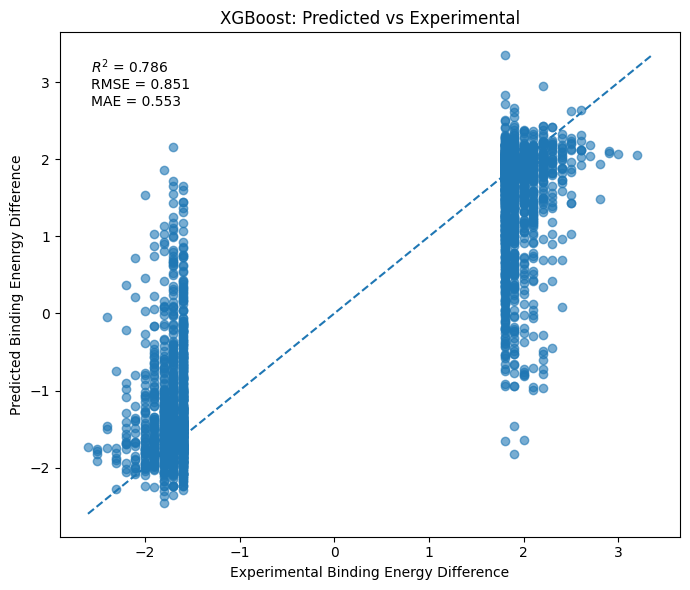

In [43]:
#==================================================================
# PLOTS
# Predicted vs Experimental 
#==================================================================
plt.figure(figsize=(7,6))
plt.scatter(y_test, best_predictions, alpha=0.6)
min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Experimental Binding Energy Difference")
plt.ylabel("Predicted Binding Enenrgy Difference")
plt.title(f"{best_model_name}: Predicted vs Experimental")
plt.text(0.05, 0.95, 
         f"$R^2$ = {r2_score(y_test, best_predictions):.3f}\n"
         f"RMSE = {np.sqrt(mean_squared_error(y_test, best_predictions)):.3f}\n"
         f"MAE = {mean_absolute_error(y_test, best_predictions):.3f}",
         transform = plt.gca().transAxes,
         verticalalignment="top")
plt.tight_layout()
plt.savefig("predicted_vs_experimental.png", dpi=300, bbox_inches="tight")
plt.show()

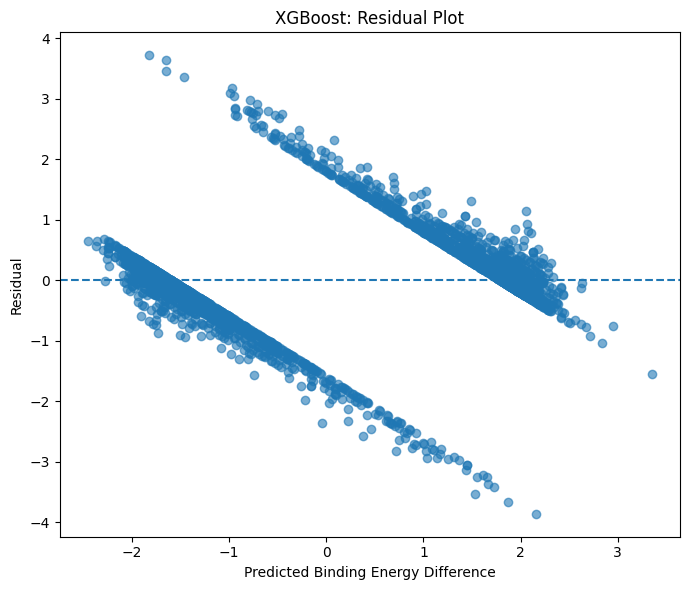

In [44]:
#===============================================================
# Residueal plot
#===============================================================
residuals = y_test.values - best_predictions
plt.figure(figsize=(7, 6))
plt.scatter(best_predictions, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Binding Energy Difference")
plt.ylabel("Residual")
plt.title(f"{best_model_name}: Residual Plot")
plt.tight_layout()
plt.savefig("residual_plot.png", dpi=300, bbox_inches="tight")
plt.show()

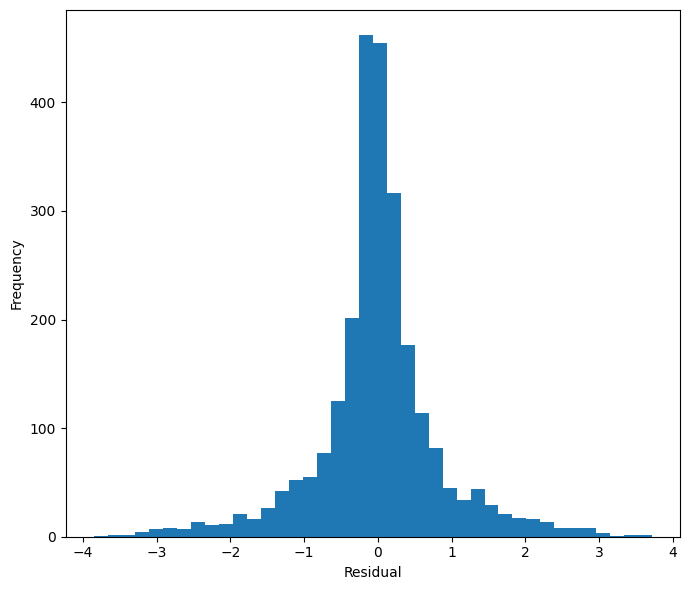

In [46]:
#=======================================================================
# Residual distribution
#=======================================================================
plt.figure(figsize=(7,6))
plt.hist(residuals, bins=40)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("residual_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

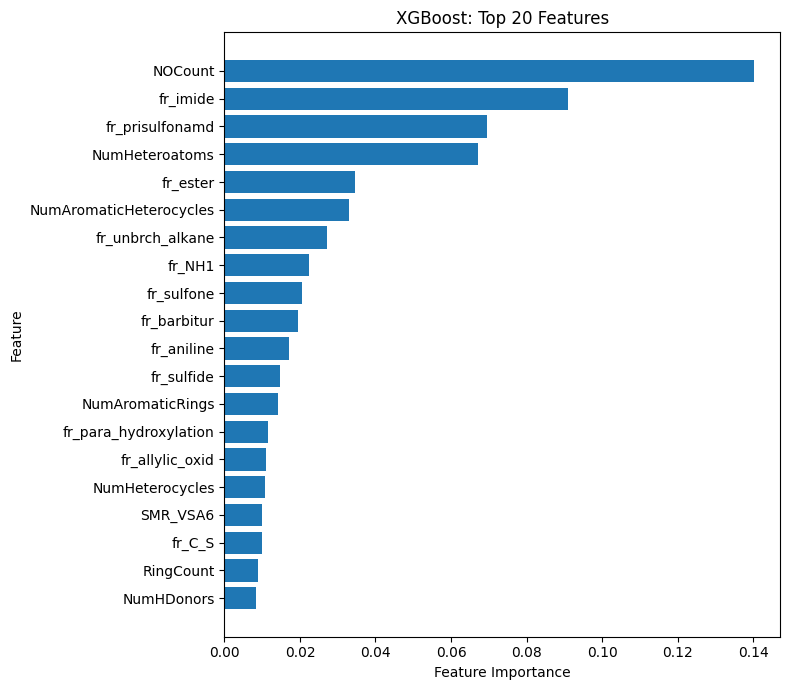

In [47]:
#=========================================================================
# Feature Importance
#=========================================================================

if best_model_name in ["XGBoost", "Random Forest", "CatBoost", "LightGBM"]:
    top_features = (feature_importance_df.head(20).sort_values("Importance"))
    plt.figure(figsize=(8, 7))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.title(f"{best_model_name}: Top 20 Features")
    plt.tight_layout()
    plt.savefig("top_20_feature_importance.png", dpi=300, bbox_inches="tight")
    plt.show()